# 04 · Perfilamiento de segmentos y estrategias de marketing

**Objetivo:** describir con datos cada uno de los 4 segmentos del modelo final (K-Means, k = 4), contrastarlos con el
baseline RFM y con la marca de clientes atípicos de DBSCAN, analizar su estacionalidad y, **solo después**, darles un
nombre y proponer estrategias con acción, momento y KPI.

Los segmentos están numerados de 0 a 3 de menor a mayor gasto mediano (notebook 03). Los colores de cada segmento son
fijos y se usan igual en la app.

In [1]:
import json
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from segmentacion import config
from segmentacion.catalogo import CUENTAS_CLAVE, SEGMENTOS
from segmentacion.features import VARIABLES_CLUSTERING
from segmentacion.perfilamiento import (MESES_TEMPORADA, facturas_por_mes, indicadores_segmento, medias_estandarizadas,
                                        pais_principal, percentiles_medios, perfil_variables, productos_top,
                                        resumen_segmentos)
from segmentacion.visualizacion import (COLOR_BORDE_CUENTA_CLAVE, COLORES_SEGMENTO, MARCADOR_CUENTA_CLAVE, estilo,
                                        guardar_figura)

estilo()
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 25)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

clientes = pd.read_parquet(config.PARQUET_SEGMENTADOS)
ventas = pd.read_parquet(config.PARQUET_LIMPIO)
preprocesador = joblib.load(config.PREPROCESADOR)
segmento = clientes["segmento"]
SEGS = sorted(segmento.unique())
print(f"{len(clientes):,} clientes · segmentos: {SEGS}")

4,324 clientes · segmentos: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


## 1. Tamaño y peso en ingresos

In [2]:
resumen = resumen_segmentos(clientes, segmento)
resumen

,clientes,pct_clientes,pct_ingresos,pct_una_compra,recency_mediana,frequency_mediana,ticket_promedio_mediana,productos_distintos_mediana,monetary_mediana
segmento,,,,,,,,,
0,1040,24.05,2.72,67.50,165.00,1.00,139.34,9.00,176.92
1,1226,28.35,15.79,53.18,110.00,1.00,417.92,32.00,655.66
2,1170,27.06,11.29,12.74,23.00,3.00,228.74,44.00,700.22
3,888,20.54,70.21,0.00,11.00,8.00,381.85,123.00,"3,098.15"


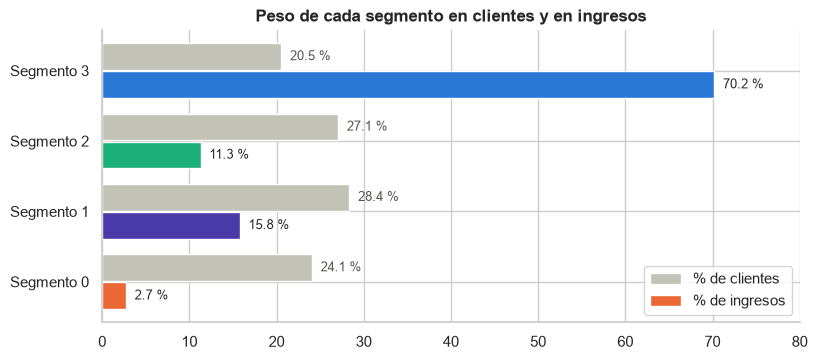

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(SEGS))
ax.barh(y + 0.2, resumen.loc[SEGS, "pct_clientes"], height=0.38, color="#c3c2b7", label="% de clientes")
ax.barh(y - 0.2, resumen.loc[SEGS, "pct_ingresos"], height=0.38, color=[COLORES_SEGMENTO[s] for s in SEGS], label="% de ingresos")
for i, s in enumerate(SEGS):
    ax.text(resumen.loc[s, "pct_ingresos"] + 1, i - 0.2, f"{resumen.loc[s, 'pct_ingresos']:.1f} %", va="center", fontsize=9)
    ax.text(resumen.loc[s, "pct_clientes"] + 1, i + 0.2, f"{resumen.loc[s, 'pct_clientes']:.1f} %", va="center", fontsize=9, color="#52514e")
ax.set_yticks(y, [f"Segmento {s}" for s in SEGS])
ax.set_xlim(0, 80)
ax.set_title("Peso de cada segmento en clientes y en ingresos")
ax.legend(loc="lower right")
guardar_figura(fig, "04_peso_segmentos")
plt.show()

In [4]:
VARIABLES_PERFIL = ["recency", "frequency", "monetary", "ticket_promedio", "productos_distintos", "antiguedad",
                    "dias_entre_compras", "unidades_por_factura", "tasa_devoluciones"]
perfil = perfil_variables(clientes, segmento, VARIABLES_PERFIL)
perfil["mediana"].T

segmento,0,1,2,3
recency,165.00,110.00,23.00,11.00
frequency,1.00,1.00,3.00,8.00
monetary,176.92,655.66,700.22,"3,098.15"
ticket_promedio,139.34,417.92,228.74,381.85
productos_distintos,9.00,32.00,44.00,123.00
antiguedad,219.50,222.00,212.00,335.00
dias_entre_compras,62.57,73.78,69.03,35.50
unidades_por_factura,73.00,250.17,136.29,232.15
tasa_devoluciones,0.00,0.00,0.00,0.00


In [5]:
perfil['media'].T

segmento,0,1,2,3
recency,169.15,141.94,30.68,20.06
frequency,1.51,1.82,3.29,11.96
monetary,217.24,"1,070.28",802.09,"6,571.75"
ticket_promedio,150.36,587.91,251.74,491.83
productos_distintos,11.85,43.37,51.08,157.17
antiguedad,206.96,206.44,195.94,305.12
dias_entre_compras,84.62,90.94,89.05,39.96
unidades_por_factura,93.92,356.62,162.31,290.89
tasa_devoluciones,0.01,0.01,0.01,0.01


**Hallazgos — tamaño y valor**

- **Segmento 3:** es el **20,5 % de los clientes y genera el 70,2 % de los ingresos**. Su cliente mediano compró hace 11
  días, lleva 8 facturas, 123 productos distintos y 3.098 £ de gasto. Es el más antiguo (335 días de mediana frente a
  212–222 en el resto) y el que repite más rápido (35,5 días entre compras frente a 62–74).
- **Segmento 1:** 28,4 % de los clientes y 15,8 % de los ingresos. Tiene el **ticket más alto** (417,92 £ de mediana) y
  las facturas con más unidades (250), pero una sola factura de mediana y 110 días sin comprar.
- **Segmento 2:** 27,1 % de los clientes y 11,3 % de los ingresos. Clientes recientes (23 días) con 3 facturas y ticket
  medio (228,74 £).
- **Segmento 0:** 24,1 % de los clientes y solo el 2,7 % de los ingresos. Una factura, ticket de 139,34 £, 9 productos y
  73 unidades por factura (todo lo más bajo).
- Las medias superan a las medianas en todos los segmentos (por ejemplo, en el segmento 1 el gasto medio es de
  1.070,28 £ frente a una mediana de 655,66 £): dentro de cada segmento sigue habiendo clientes muy grandes. Por eso se
  describe con medianas.

## 2. Snake plot y radar

- **Snake plot:** media de cada variable de clustering **estandarizada** (0 = cliente medio, ±1 = una desviación típica)
  por segmento. Es la "firma" del segmento en el espacio donde K-Means lo encontró.
- **Radar:** percentil medio de los clientes del segmento en cada variable (0–100, misma escala para todas). La recencia
  se invierte para que "más alto = mejor" en todos los ejes.

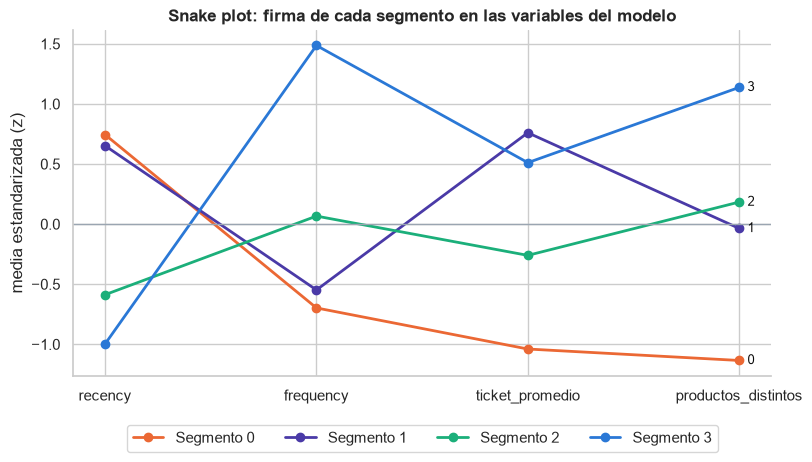

,recency,frequency,ticket_promedio,productos_distintos
segmento,,,,
0,0.74,-0.70,-1.04,-1.13
1,0.65,-0.55,0.76,-0.04
2,-0.59,0.07,-0.26,0.18
3,-1.00,1.49,0.51,1.14


In [6]:
Z = preprocesador.transform(clientes[VARIABLES_CLUSTERING])
snake = medias_estandarizadas(Z, segmento.to_numpy(), VARIABLES_CLUSTERING)
fig, ax = plt.subplots(figsize=(9, 4.5))
for s in SEGS:
    ax.plot(VARIABLES_CLUSTERING, snake.loc[s], marker="o", lw=2, color=COLORES_SEGMENTO[s], label=f"Segmento {s}")
    ax.annotate(f"{s}", (len(VARIABLES_CLUSTERING) - 1, snake.loc[s].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                color="#0b0b0b", fontsize=9, va="center")
ax.axhline(0, color="#9AA5B1", lw=1)
ax.set_ylabel("media estandarizada (z)")
ax.set_title("Snake plot: firma de cada segmento en las variables del modelo")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
guardar_figura(fig, "04_snake_plot")
plt.show()
snake

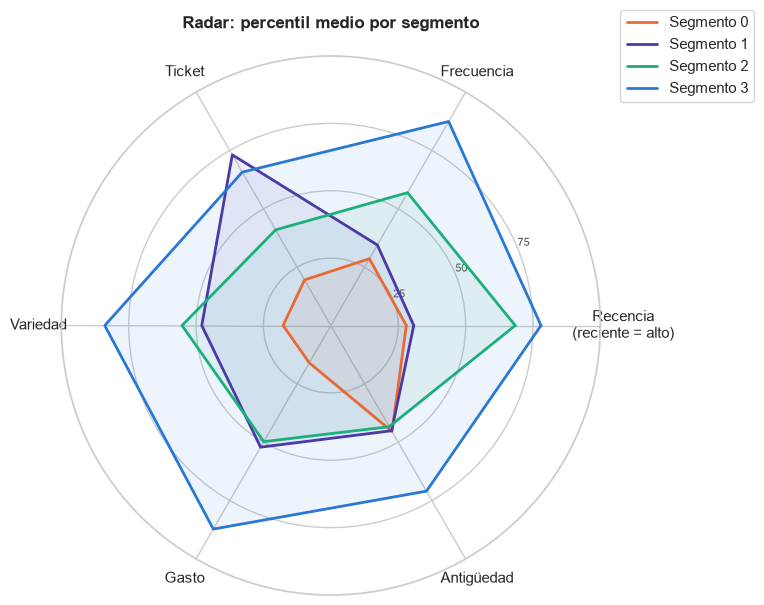

,recency,frequency,ticket_promedio,productos_distintos,monetary,antiguedad
segmento,,,,,,
0,28.00,28.61,19.53,17.71,16.00,45.41
1,30.77,34.50,73.13,47.89,52.13,45.10
2,68.42,56.91,40.97,55.22,49.77,43.35
3,77.99,87.42,65.71,83.89,87.23,70.97


In [7]:
VARIABLES_RADAR = ["recency", "frequency", "ticket_promedio", "productos_distintos", "monetary", "antiguedad"]
ETIQUETAS_RADAR = ["Recencia\n(reciente = alto)", "Frecuencia", "Ticket", "Variedad", "Gasto", "Antigüedad"]
radar = percentiles_medios(clientes, segmento.to_numpy(), VARIABLES_RADAR, invertir=("recency",))
angulos = np.linspace(0, 2 * np.pi, len(VARIABLES_RADAR), endpoint=False).tolist()
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"polar": True})
for s in SEGS:
    valores = radar.loc[s].tolist()
    ax.plot(angulos + angulos[:1], valores + valores[:1], lw=2, color=COLORES_SEGMENTO[s], label=f"Segmento {s}")
    ax.fill(angulos + angulos[:1], valores + valores[:1], color=COLORES_SEGMENTO[s], alpha=0.08)
ax.set_xticks(angulos, ETIQUETAS_RADAR)
ax.set_ylim(0, 100)
ax.set_yticks([25, 50, 75], ["25", "50", "75"], color="#52514e", fontsize=8)
ax.set_title("Radar: percentil medio por segmento", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
guardar_figura(fig, "04_radar")
plt.show()
radar

**Hallazgos — snake plot y radar**

- **Segmento 0:** está por debajo de la media en todo. Lo que más lo distingue es el **ticket (−1,04 desviaciones
  típicas) y la variedad (−1,13)**, más que la recency (+0,74).
- **Segmento 1:** tiene casi la misma recency que el 0 (+0,65) y también poca frecuencia (−0,55), pero el **ticket más
  alto de todos (+0,76)**. En el radar su percentil de ticket (73,1) supera incluso al del segmento 3 (65,7). La
  diferencia entre los segmentos 0 y 1 es el tamaño del pedido, no la actividad.
- **Segmento 2:** destaca solo por la recencia (−0,59, es decir, compraron hace poco); en lo demás está cerca de la media.
  En el radar ocupa el centro en todas las variables menos en recencia (percentil 68,4).
- **Segmento 3:** está muy por encima en frecuencia (+1,49) y variedad (+1,14) y es el más reciente (−1,00). En el radar
  domina en todos los ejes salvo el ticket, y es el único con antigüedad alta (percentil 71,0 frente a 43–45 del resto).